In [1]:
# IPython magic commands
%load_ext autoreload
%autoreload 2
%autosave 600

# Standard libraries
import sys
import warnings
from datetime import datetime

# Suppress warnings
def warn(*args, **kwargs):
    pass
warnings.warn = warn

# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

sys.path.append("../")

Autosaving every 600 seconds


In [ ]:
!pip install gdown
import gdown

url = "https://drive.google.com/file/d/1f9Vx8MDbJubHXtnFgdkOQRymnzXXCxF3/view?usp=share_link"
output = "../data/df_preprocessed_with_targets.csv"
gdown.download(url, output, quiet=False)
df_preprocessed_with_targets = pd.read_csv(output, index_col=False)

df_preprocessed_with_targets.replace(r"^\s*missing\s*$", np.nan, regex=True, inplace=True)

In [3]:
df_preprocessed_with_targets.head()

,AriaLabel,AriaName,Composer,AriEmozione 1,Annotator A,Annotator B,LLM-Proposed-LargeTax: Phi4,LLM-Proposed-SmallTax: AnnA × Phi4,LLM-Proposed-SmallTax: AnnB × Phi4,LLM-Proposed-SmallTax: AriEm1 × Phi4,...,TimeSignature_3/4,TimeSignature_3/8,TimeSignature_4/2,TimeSignature_4/4,TimeSignature_6/4,TimeSignature_6/8,TimeSignature_9/8,TimeSignatureGrouped_compound triple,TimeSignatureGrouped_simple duple,TimeSignatureGrouped_simple triple
0,Ale01M,E_prezzo,Leonardo Vinci,admiration,NaN,NaN,contempt,pride,satisfaction,contempt,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,Ale01M,E_prezzo,Georg Friedrich Händel,admiration,NaN,NaN,contempt,pride,satisfaction,contempt,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,Ale01M,E_prezzo,Johann Adolph Hasse,admiration,NaN,NaN,contempt,pride,satisfaction,contempt,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,Ale01M,E_prezzo,Baldassare Galuppi,admiration,NaN,NaN,contempt,pride,satisfaction,contempt,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,Ale01M,E_prezzo,Michele Caballone,admiration,NaN,NaN,contempt,pride,satisfaction,contempt,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [4]:
passions_systems = [    
    "AriEmozione 1",
    "Annotator A",
    "Annotator B",
    "LLM-Proposed-LargeTax: Phi4",
    "LLM-Proposed-SmallTax: AnnA × Phi4",
    "LLM-Proposed-SmallTax: AnnB × Phi4",
    "LLM-Proposed-SmallTax: AriEm1 × Phi4",
    "LLM-DescartesTax: Phi4",
    "LLM-HumanTax: AnnA × Phi4",
    "LLM-HumanTax: AnnB × Phi4",
    "LLM-HumanTax: AriEm1 × Phi4",
    "LLM-Proposed-LargeTax: Gemma",
    "LLM-Proposed-SmallTax: AnnA × Gemma",
    "LLM-Proposed-SmallTax: AnnB × Gemma",
    "LLM-Proposed-SmallTax: AriEm1 × Gemma",
    "LLM-DescartesTax: Gemma",
    "LLM-HumanTax: AnnA × Gemma",
    "LLM-HumanTax: AnnB × Gemma",
    "LLM-HumanTax: AriEm1 × Gemma"]

## Reduce features dimensions with PCA

In [5]:
df_total_without_targets = df_preprocessed_with_targets.drop(columns=passions_systems + ['AriaLabel', 'AriaName', 'Composer'])

df_metadata_reduced = df_preprocessed_with_targets[['AriaLabel','AriaName'] + passions_systems]

In [6]:
from utils.modeling_functions import  PCAConfig, PCAReductionPipeline
from utils.group_musif_features import module_regex_map

# Create config
config = PCAConfig(
    mode="modular",
    var_ratio_per_module=0.90,
    var_ratio_global=0.90,
    musical_features=["texture", "melody", "harmony", "rhythm", "dynamics", "core", "unknown"]
)

# Fit pipeline
pipeline = PCAReductionPipeline(config)
df_stage1, df_final = pipeline.fit(df_total_without_targets)
X_global_reduced = df_final.to_numpy()

# Print summary
summary_df = pipeline.print_summary()
print(f"\nFinal feature matrix shape: {df_final.shape}")
print(f"Reduction mode: {config.mode}")

  texture     : 1402 →  40 ( 35.3% variance)
  melody      : 12727 →  35 ( 56.1% variance)
  core        :  70 →  18 ( 90.3% variance)
  harmony     : 1971 →  30 ( 48.8% variance)
  rhythm      : 359 →  35 ( 34.5% variance)
  dynamics    : 143 →  29 ( 90.2% variance)

PCA Reduction Summary
Mode: modular
Variance ratio (per-module): 0.9

  module  orig_dim  reduced_dim  explained_var_ratio_sum note
    core        70           18                 0.903247     
dynamics       143           29                 0.902354     
 harmony      1971           30                 0.488079     
  melody     12727           35                 0.561129     
  rhythm       359           35                 0.344882     
 texture      1402           40                 0.353013     

Module caps applied: {'texture': 40, 'melody': 35, 'scale': 25, 'unknown': 30, 'harmony': 30, 'rhythm': 35}

Final feature matrix shape: (1668, 187)
Reduction mode: modular


In [7]:
# Join level names with an underscore
df_final_flattened = df_final.copy()
df_final_flattened.columns = ['_'.join(col) for col in df_final_flattened.columns]

# Join resulting PCAs with metadata (shape is obviously larger)
df_pcas = df_final_flattened.merge(df_metadata_reduced, left_index=True, right_index=True, how='left')
df_pcas.shape

(1668, 208)

## Find outliers with hybrid outlier detector

In [8]:
from utils.utils_outliers import *
from sklearn.covariance import LedoitWolf
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
import umap

# ============================================================
# PREP NEW STORAGE FOR PCA RESULTS (for classification later)
# ============================================================

# ----------------------------------------------------
# MAIN LOOP OUTLIER DETECTION
# ----------------------------------------------------

arias = df_pcas['AriaName'].unique()

all_umap = []
all_labels = []
all_scores = []
all_outliers = []
all_aria_names = []
all_orig_indices = []

outlier_summary = {}
outlier_details = {}

selected_percentiles = {}
selected_kl_values = {}

for aria in arias:
    print(f"\n== Processing Aria: {aria} ==")

    # ---------------------------------------------
    # 1. Load aria subset
    # ---------------------------------------------
    df_aria = df_preprocessed_with_targets[df_preprocessed_with_targets["AriaName"] == aria].copy()

    df_aria["orig_index"] = df_aria.index

    # Extract numerical matrix
    orig_indices = df_aria["orig_index"].values

    # ---------------------------------------------
    # 2. Scaling + PCA
    # ---------------------------------------------
    # Get rows corresponding to this aria
    aria_mask = df_preprocessed_with_targets["AriaName"] == aria
    X_pca = X_global_reduced[aria_mask.values]

    ## Calculate outliers
    # ---------------------------------------------
    # 3. Mahalanobis
    # ---------------------------------------------
    cov = LedoitWolf().fit(X_pca)
    mahal = cov.mahalanobis(X_pca)
    M = (mahal - mahal.min()) / (mahal.max() - mahal.min() + 1e-8)

    # ---------------------------------------------
    # 4. One-Class SVM
    # ---------------------------------------------
    ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.1)
    ocsvm.fit(X_pca)
    oc_scores = -ocsvm.score_samples(X_pca)
    OC = (oc_scores - oc_scores.min()) / (oc_scores.max() - oc_scores.min() + 1e-8)

    # ---------------------------------------------
    # 5. Local Outlier Factor
    # ---------------------------------------------
    neighbors = min(4, len(X_pca)-1)
    neighbors = [1 if neighbors is None or neighbors < 1 else neighbors][0]
    lof = LocalOutlierFactor(n_neighbors=neighbors)
    lof.fit(X_pca)
    lof_scores = -lof.negative_outlier_factor_
    L = (lof_scores - lof_scores.min()) / (lof_scores.max() - lof_scores.min() + 1e-8)

    # ---------------------------------------------
    # 6. Hybrid model
    # ---------------------------------------------
    alpha, beta, gamma, hybrid_score, kl_value = tune_hybrid_weights_KL(M, OC, L, step=0.05)
    # print(alpha, beta, gamma, hybrid_score)

    # ---------------------------------------------
    # 7. UMAP embedding
    # ---------------------------------------------
    reducer = umap.UMAP(n_components=2, random_state=42)
    X_umap = reducer.fit_transform(X_pca)
    
    # Plots
    # plot_scores(X_umap, M, "Mahalanobis Distance", aria)
    # plot_scores(X_umap, OC, "One-Class SVM", aria)
    # plot_scores(X_umap, L, "Local Outlier Factor", aria)
    # plot_scores(X_umap, hybrid_score, "Hybrid Score", aria)

    # ---------------------------------------------
    # 8. DEFINE OUTLIERS — ALL ABOVE PERCENTILE
    # ---------------------------------------------
    percentile, kl_val = select_percentile_KL(
        hybrid_score,
        candidate_percentiles=[70, 80, 85, 90, 95],
        bins=25
    )

    th = np.percentile(hybrid_score, percentile)
    outlier_idx_local = np.where(hybrid_score >= th)[0]
    selected_percentiles[aria] = percentile
    selected_kl_values[aria] = kl_val

    # ---------------------------------------------
    # 9. Store for global dataset
    # ---------------------------------------------
    for i in range(len(X_umap)):
        all_umap.append(X_umap[i])
        all_labels.append(aria)
        all_scores.append(hybrid_score[i])
        all_orig_indices.append(orig_indices[i])
        all_outliers.append(i in outlier_idx_local)
        all_aria_names.append(aria)

    # Per-aria summary
    outlier_summary[aria] = len(outlier_idx_local)

    outlier_details[aria] = {
        "indices_local": outlier_idx_local.tolist(),
        "indices_global": orig_indices[outlier_idx_local].tolist(),
        "scores": hybrid_score[outlier_idx_local].tolist(),
        "umap_coords": X_umap[outlier_idx_local].tolist()
    }

# ----------------------------------------------------
# FINAL DATAFRAME WITH METADATA
# ----------------------------------------------------
df_plot = pd.DataFrame({
    "UMAP1": [p[0] for p in all_umap],
    "UMAP2": [p[1] for p in all_umap],
    "HybridScore": all_scores,
    "IsOutlier": all_outliers,
    "AriaName": all_aria_names,
    "orig_index": all_orig_indices
})

df_plot = df_plot.merge(
    df_metadata_reduced.drop(columns=['AriaName']),    
    left_on='orig_index',
    right_index=True,   
    suffixes=('', '_meta')
)

# print("\n=== FINAL DATAFRAME (first rows) ===")
# print(df_plot.head())
print("\n=== OUTLIER SUMMARY ===")
print(outlier_summary)


== Processing Aria: E_prezzo ==

== Processing Aria: Vedrai_con ==

== Processing Aria: Vil_trofeo ==

== Processing Aria: Chi_vive ==

== Processing Aria: O_sugli ==

== Processing Aria: Se_possono ==

== Processing Aria: Voi_che ==

== Processing Aria: Se_amore ==

== Processing Aria: Non_sarei ==

== Processing Aria: Senza_procelle ==

== Processing Aria: Digli_che ==

== Processing Aria: Destrier_che ==

== Processing Aria: E_ver ==

== Processing Aria: Se_e ==

== Processing Aria: Se_il ==

== Processing Aria: Se_viver ==

== Processing Aria: Di_rendermi ==

== Processing Aria: Se_troppo ==

== Processing Aria: Serbati_a ==

== Processing Aria: Finche_rimango ==

== Processing Aria: Dove_si ==

== Processing Aria: Mio_ben ==

== Processing Aria: Son_confusa ==

== Processing Aria: Ombra_dell ==

== Processing Aria: Conservati_fedele ==

== Processing Aria: Fra_cento ==

== Processing Aria: Su_le ==

== Processing Aria: Per_pieta_bell ==

== Processing Aria: Deh_respirar ==

== Pr

In [9]:
df_plot = df_plot.merge(
    df_metadata_reduced.drop(columns=['AriaName']),    
    left_on='orig_index',
    right_index=True,   
    suffixes=('', '_meta')
)


print("\n=== OUTLIER SUMMARY ===")
print(outlier_summary)


=== OUTLIER SUMMARY ===
{'E_prezzo': 2, 'Vedrai_con': 4, 'Vil_trofeo': 4, 'Chi_vive': 4, 'O_sugli': 2, 'Se_possono': 3, 'Voi_che': 2, 'Se_amore': 2, 'Non_sarei': 3, 'Senza_procelle': 2, 'Digli_che': 4, 'Destrier_che': 3, 'E_ver': 2, 'Se_e': 3, 'Se_il': 2, 'Se_viver': 2, 'Di_rendermi': 2, 'Se_troppo': 3, 'Serbati_a': 2, 'Finche_rimango': 2, 'Dove_si': 3, 'Mio_ben': 3, 'Son_confusa': 2, 'Ombra_dell': 2, 'Conservati_fedele': 3, 'Fra_cento': 3, 'Su_le': 2, 'Per_pieta_bell': 2, 'Deh_respirar': 2, 'Sogna_il': 2, 'Bramar_di': 3, 'Non_ti': 2, 'Torna_innocente': 2, 'Vo_solcando': 1, 'Rendimi_il': 2, 'Mi_scacci': 2, 'Amalo_e': 1, 'Non_temer_chio': 2, 'Se_dun': 2, 'Se_del': 2, 'Per_quel': 3, 'Va_tra': 3, 'Cosi_stupisce': 2, 'Nuvoletta_opposta': 2, 'Figlio_se': 2, 'Mi_credi': 2, 'Non_e': 2, 'Per_lei': 4, 'Non_curo': 3, 'Il_suo': 2, 'Se_ardire': 2, 'Prudente_mi': 3, 'Se_tronca': 2, 'Se_tutti': 4, 'Felice_eta': 2, 'Perfidi_gia': 3, 'Non_odi': 2, 'Nel_tuo': 2, 'Misero_pargoletto': 4, 'Odo_il': 3, 'N

### Plot Arias Outliers in 2 dimensions with UMAP

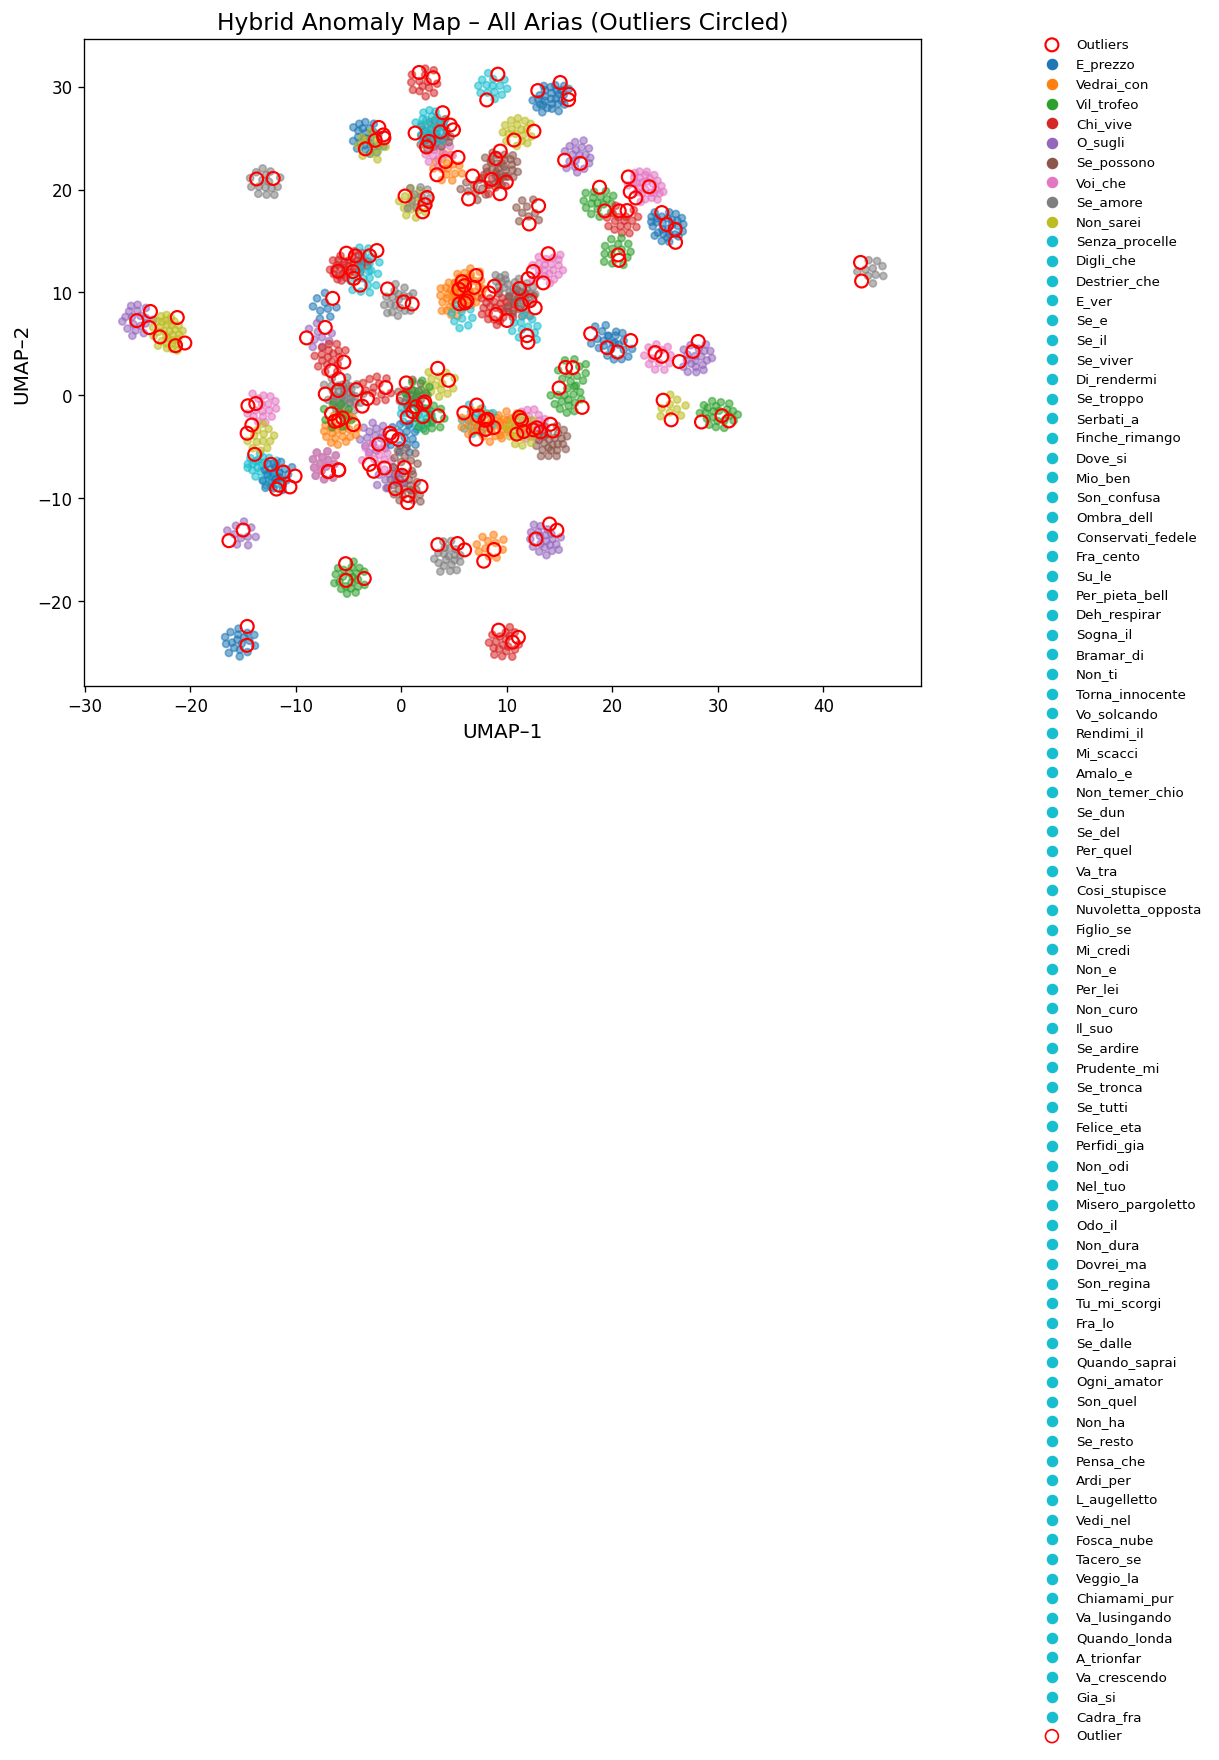

In [10]:
from utils.utils_outliers import plot_umap

plot_umap(df_plot)

### Get outliers stats 

In [11]:
# 1. To see a detailed printout for each column:
for col in passions_systems:
    if col in df_metadata_reduced.columns:
        print(f"--- Counts for {col} ---")
        print(df_metadata_reduced[col].value_counts())
        print("\n")

# 2. Alternatively, to create a summary table (DataFrame) where:
label_counts_summary = df_metadata_reduced[passions_systems].apply(pd.Series.value_counts).fillna(0).astype(int)

print("Summary Table:")
print(label_counts_summary)

--- Counts for AriEmozione 1 ---
AriEmozione 1
sadness       479
anger         458
admiration    282
love          183
fear          168
joy            72
Name: count, dtype: int64


--- Counts for Annotator A ---
Annotator A
pity            238
anger           167
boldness         95
contempt         94
fear             87
sadness          84
esteem           78
love             66
hope             56
irresolution     55
despair          51
abjectness       47
repentance       40
Name: count, dtype: int64


--- Counts for Annotator B ---
Annotator B
anger              160
pity               126
love               120
sadness            111
irresolution       103
despair             98
boldness            67
confidence          61
generosity          59
fear                54
despair,sadness     48
Name: count, dtype: int64


--- Counts for LLM-Proposed-LargeTax: Phi4 ---
LLM-Proposed-LargeTax: Phi4
despair         535
hope            218
pride           178
contempt        160
anticip

In [12]:
df_class = df_pcas.merge(
    df_plot[['IsOutlier', 'orig_index']],
    left_index=True,           # use the left DF's index
    right_on='orig_index',     # match to the right DF's column
    how='left'
).drop(columns=['orig_index'])

### Load data from here avoiding preprocessing, outlier detection and PCA

In [13]:
# df_class = pd.read_csv('../data/3_Paper_PCA_data.csv', index_col=False)

## Classify emotions

In [ ]:

from utils.utils_classification import (
    evaluate_grouped,
    imbalance_ratio,
    entropy_balance,
    bootstrap_ci,
    _make_grouped_splits,
)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import silhouette_score, f1_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import wilcoxon
from scipy import stats as scipy_stats
import numpy as np   
import pandas as pd  


# ----------------------------------------------------------------------
# ACCUMULATORS
# ----------------------------------------------------------------------
results_summary   = []
all_label_rows    = []
detailed_reports  = {}
silhouette_scores = {}
stat_results      = []
f1_store          = {}

results_summary = []
all_label_rows = []
detailed_reports = {}
silhouette_scores = {}
stat_results = []
f1_store = {}
n_splits = 10
TEST_SIZE    = 0.20
RANDOM_STATE = 42
C_LOGREG     = 1.0
MAX_ITER     = 5000

for emotions_set_target in passions_systems:
    print("\n=========================================")
    print(f"🏷️  MODELING LABEL: {emotions_set_target}")
    print("=========================================")

    # 1️⃣ fresh copy every iteration
    df_target = df_class.copy()

    # 2️⃣ drop NA safely — reset_index so row alignment is guaranteed
    df_target = df_target.dropna(
        subset=[emotions_set_target]).reset_index(drop=True)

    # ── With outliers ─────────────────────────────────────────────────
    X_all      = df_target[df_final_flattened.columns].values
    y_all      = df_target[emotions_set_target].values
    groups_all = df_target['AriaName'].values          # aria-level groups

    # ── Without outliers ──────────────────────────────────────────────
    df_clean   = df_target[~df_target["IsOutlier"]].reset_index(drop=True)
    X_without  = df_clean[df_final_flattened.columns].values
    y_without  = df_clean[emotions_set_target].values
    groups_wo  = df_clean['AriaName'].values            # aria-level groups

    # --------------------------------------------------
    # CLASS DISTRIBUTION DIAGNOSTICS
    # --------------------------------------------------
    n_classes_with    = len(np.unique(y_all))
    n_classes_without = len(np.unique(y_without))
    imb_with          = imbalance_ratio(y_all)
    imb_without       = imbalance_ratio(y_without)
    ent_with          = entropy_balance(y_all)
    ent_without       = entropy_balance(y_without)

    print(f"\nSample sizes  → with outliers: {len(y_all)} | without: {len(y_without)}")
    print(f"N classes     → with: {n_classes_with} | without: {n_classes_without}")
    print(f"N arias       → with: {len(np.unique(groups_all))} | "
          f"without: {len(np.unique(groups_wo))}")
    print(f"Imbalance ratio → with: {imb_with} | without: {imb_without}")
    print(f"Entropy balance → with: {ent_with} | without: {ent_without}")
    print(f"\nClass distribution (with outliers):\n"
          f"{pd.Series(y_all).value_counts().to_string()}")
    print(f"\nClass distribution (without outliers):\n"
          f"{pd.Series(y_without).value_counts().to_string()}")

    # --------------------------------------------------
    # SILHOUETTE SCORES
    # --------------------------------------------------
    sil_all = sil_clean = None
    if n_classes_with > 1 and len(X_all) > 1:
        sil_all = silhouette_score(X_all, y_all, metric="euclidean")
        print(f"\nSilhouette (with outliers):    {sil_all:.3f}")
    if n_classes_without > 1 and len(X_without) > 1:
        sil_clean = silhouette_score(X_without, y_without, metric="euclidean")
        print(f"Silhouette (without outliers): {sil_clean:.3f}")

    silhouette_scores[emotions_set_target] = {
        "with_outliers":    sil_all,
        "without_outliers": sil_clean,
    }

    # --------------------------------------------------
    # SCHEME-LEVEL EVALUATION — aria-level grouped splitting
    # evaluate_grouped is left UNTOUCHED (identical to both cells)
    # --------------------------------------------------
    res_with = evaluate_grouped(
        X_all, y_all, groups_all,
        n_splits=n_splits, test_size=TEST_SIZE,
        random_state=RANDOM_STATE, C=C_LOGREG, max_iter=MAX_ITER,
        dummy_mode="stratified"
    )
    res_wo = evaluate_grouped(
        X_without, y_without, groups_wo,
        n_splits=n_splits, test_size=TEST_SIZE,
        random_state=RANDOM_STATE, C=C_LOGREG, max_iter=MAX_ITER,
        dummy_mode="stratified"
    )

    # --------------------------------------------------
    # PER-LABEL F1 + DUMMY + SKILL  (without outliers)
    # same grouped splits as evaluate_grouped; one pass fits both
    # the LogReg (on scaled X) and the stratified dummy (on raw X).
    # --------------------------------------------------
    all_labels_wo = np.unique(y_without)
    splits_wo = list(_make_grouped_splits(
        X_without, y_without, groups_wo,
        n_splits=n_splits, test_size=TEST_SIZE, random_state=RANDOM_STATE
    ))

    split_label_f1s       = {label: [] for label in all_labels_wo}
    split_label_dummy_f1s = {label: [] for label in all_labels_wo}

    clf_label = LogisticRegression(
        C=C_LOGREG, solver="saga", max_iter=MAX_ITER,
        class_weight="balanced", random_state=RANDOM_STATE
    )
    dummy_label = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)

    for train_idx, test_idx in splits_wo:
        X_tr, X_te = X_without[train_idx], X_without[test_idx]
        y_tr, y_te = y_without[train_idx], y_without[test_idx]

        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)

        # LogReg per-label F1 (scaled features)
        clf_label.fit(X_tr_s, y_tr)
        y_pred = clf_label.predict(X_te_s)
        f1s = f1_score(
            y_te, y_pred,
            labels=all_labels_wo, average=None, zero_division=0
        )
        for label, score in zip(all_labels_wo, f1s):
            split_label_f1s[label].append(score)

        # Stratified dummy per-label F1 (dummy ignores X; scaling irrelevant)
        dummy_label.fit(X_tr, y_tr)
        y_pred_dummy = dummy_label.predict(X_te)
        f1s_dummy = f1_score(
            y_te, y_pred_dummy,
            labels=all_labels_wo, average=None, zero_division=0
        )
        for label, score in zip(all_labels_wo, f1s_dummy):
            split_label_dummy_f1s[label].append(score)

    # Aggregate per-label F1, dummy F1, and skill across folds
    label_rows = []
    for label in all_labels_wo:
        scores       = np.array(split_label_f1s[label])
        scores_dummy = np.array(split_label_dummy_f1s[label])

        mean_f1    = float(np.mean(scores))
        mean_dummy = float(np.mean(scores_dummy))

        se = scipy_stats.sem(scores)
        ci_lo, ci_hi = scipy_stats.t.interval(
            0.95, df=len(scores) - 1, loc=mean_f1, scale=se
        )

        # Point-estimate skill: ratio of means (matches paper's reported skill)
        skill = (mean_f1 - mean_dummy) / (1 - mean_dummy) \
            if (1 - mean_dummy) > 0 else float('nan')

        # Skill CI: distribution of per-fold skills (mean-of-ratios)
        fold_skills = [
            (f - d) / (1 - d)
            for f, d in zip(scores, scores_dummy)
            if (1 - d) > 0
        ]
        fold_skills = np.array(fold_skills)
        if len(fold_skills) > 1:
            se_sk = scipy_stats.sem(fold_skills)
            sk_ci_lo, sk_ci_hi = scipy_stats.t.interval(
                0.95, df=len(fold_skills) - 1,
                loc=float(np.mean(fold_skills)), scale=se_sk
            )
        else:
            sk_ci_lo = sk_ci_hi = float('nan')

        label_rows.append({
            "target":      emotions_set_target,
            "label":       label,
            "support":     int(np.sum(y_without == label)),
            "mean_f1":     round(mean_f1,                    3),
            "ci_lo":       round(float(max(ci_lo, 0.0)),     3),
            "ci_hi":       round(float(ci_hi),               3),
            "dummy_f1":    round(mean_dummy,                 3),
            "skill":       round(skill,                      3),
            "skill_ci_lo": round(float(max(sk_ci_lo, -1.0)), 3),
            "skill_ci_hi": round(float(sk_ci_hi),            3),
        })

    df_label_f1 = (
        pd.DataFrame(label_rows)
        .sort_values("support", ascending=False)
        .reset_index(drop=True)
    )
    print(f"\nPer-label F1 + skill (without outliers):\n"
          f"{df_label_f1.to_string(index=False)}")

    all_label_rows.extend(label_rows)

    # --------------------------------------------------
    # SCHEME-LEVEL SCALARS (both conditions)
    # --------------------------------------------------
    f1_with       = res_with['f1_model']
    f1_wo         = res_wo['f1_model']
    f1_dummy_with = res_with['f1_dummy']
    f1_dummy_wo   = res_wo['f1_dummy']
    skill_with    = res_with['skill_arr']
    skill_wo      = res_wo['skill_arr']

    # --------------------------------------------------
    # STORE FOR CROSS-TARGET COMPARISON
    # --------------------------------------------------
    f1_store[emotions_set_target] = {
        "with":              skill_with,
        "without":           skill_wo,
        "raw_with":          f1_with,
        "raw_without":       f1_wo,
        "n_classes_with":    n_classes_with,
        "n_classes_without": n_classes_without,
        "entropy_with":      ent_with,
        "entropy_without":   ent_without,
    }

    # --------------------------------------------------
    # CONFIDENCE INTERVALS
    # --------------------------------------------------
    ci_f1_with    = bootstrap_ci(f1_with)
    ci_f1_wo      = bootstrap_ci(f1_wo)
    ci_dummy_with = bootstrap_ci(f1_dummy_with)
    ci_dummy_wo   = bootstrap_ci(f1_dummy_wo)
    ci_skill_with = bootstrap_ci(skill_with)
    ci_skill_wo   = bootstrap_ci(skill_wo)

    # --------------------------------------------------
    # WILCOXON: without > with outliers
    # --------------------------------------------------
    try:
        p_outliers = wilcoxon(f1_wo, f1_with, alternative="greater").pvalue
    except Exception:
        p_outliers = np.nan

    # p_model_vs_dummy already computed inside evaluate_grouped
    p_mdvd_with = res_with['p_model_vs_dummy']
    p_mdvd_wo   = res_wo['p_model_vs_dummy']

    # --------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------
    print("\n--- SUMMARY STATISTICS ---")
    print(f"{'Metric':<42} {'With outliers':>18} {'Without outliers':>18}")
    print("-" * 80)
    print(f"{'N samples':<42} {len(y_all):>18} {len(y_without):>18}")
    print(f"{'N classes':<42} {n_classes_with:>18} {n_classes_without:>18}")
    print(f"{'N splits used':<42} "
          f"{res_with['n_splits_used']:>18} {res_wo['n_splits_used']:>18}")
    print(f"{'Imbalance ratio (maj/min)':<42} {imb_with:>18} {imb_without:>18}")
    print(f"{'Entropy balance (0–1)':<42} {ent_with:>18} {ent_without:>18}")
    print(f"{'Mean F1 model':<42} "
          f"{np.nanmean(f1_with):>18.3f} {np.nanmean(f1_wo):>18.3f}")
    print(f"{'Mean F1 dummy':<42} "
          f"{np.nanmean(f1_dummy_with):>18.3f} {np.nanmean(f1_dummy_wo):>18.3f}")
    print(f"{'Skill score (mean)':<42} "
          f"{np.nanmean(skill_with):>18.3f} {np.nanmean(skill_wo):>18.3f}")
    print(f"{'Skill score CI':<42} "
          f"{str(ci_skill_with):>18} {str(ci_skill_wo):>18}")
    print(f"{'Wilcoxon p (model > dummy)':<42} "
          f"{p_mdvd_with:>18.4f} {p_mdvd_wo:>18.4f}")
    print(f"{'  significant?':<42} "
          f"{'✅' if p_mdvd_with < 0.05 else '—':>18} "
          f"{'✅' if p_mdvd_wo < 0.05 else '—':>18}")
    print(f"{'Wilcoxon p (without > with outliers)':<42} "
          f"{p_outliers:>18.4f} "
          f"{'✅' if not np.isnan(p_outliers) and p_outliers < 0.05 else '—':>18}")

    # --------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------
    stat_results.append({
        "Target":                        emotions_set_target,
        "N_with":                        len(y_all),
        "N_without":                     len(y_without),
        "N_classes_with":                n_classes_with,
        "N_classes_without":             n_classes_without,
        "Imbalance_ratio_with":          imb_with,
        "Imbalance_ratio_without":       imb_without,
        "Entropy_balance_with":          ent_with,
        "Entropy_balance_without":       ent_without,
        "Mean_F1_with_outliers":         round(np.nanmean(f1_with), 4),
        "Std_F1_with_outliers":          round(np.nanstd(f1_with), 4),
        "CI_with_outliers":              ci_f1_with,
        "Mean_F1_without_outliers":      round(np.nanmean(f1_wo), 4),
        "Std_F1_without_outliers":       round(np.nanstd(f1_wo), 4),
        "CI_without_outliers":           ci_f1_wo,
        "Mean_F1_dummy_with":            round(np.nanmean(f1_dummy_with), 4),
        "CI_dummy_with":                 ci_dummy_with,
        "Mean_F1_dummy_without":         round(np.nanmean(f1_dummy_wo), 4),
        "CI_dummy_without":              ci_dummy_wo,
        "Skill_Score_with":              round(np.nanmean(skill_with), 4),
        "CI_Skill_with":                 ci_skill_with,
        "Skill_Score_without":           round(np.nanmean(skill_wo), 4),
        "CI_Skill_without":              ci_skill_wo,
        "Delta_F1_outliers":             round(
            np.nanmean(f1_wo) - np.nanmean(f1_with), 4),
        "Delta_model_vs_dummy_with":     round(
            np.nanmean(f1_with) - np.nanmean(f1_dummy_with), 4),
        "Delta_model_vs_dummy_without":  round(
            np.nanmean(f1_wo) - np.nanmean(f1_dummy_wo), 4),
        "p_outliers":                    round(float(p_outliers), 4),
        "p_model_vs_dummy_with":         round(p_mdvd_with, 4),
        "p_model_vs_dummy_without":      round(p_mdvd_wo, 4),
        "Silhouette_with_outliers":      sil_all,
        "Silhouette_without_outliers":   sil_clean,
    })



# ======================================================================
# Save combined per-label F1 + skill table
# ======================================================================
df_all_label_f2 = (
    pd.DataFrame(all_label_rows)
    .sort_values(["target", "support"], ascending=[True, False])
    .reset_index(drop=True)
)
print("\n\n================ PER-LABEL F1 + SKILL SUMMARY ================")
print(df_all_label_f2.to_string(index=False))


# ======================================================================
# SUMMARY DATAFRAME
# ======================================================================
print("\n\n================ FINAL SUMMARY ================")
df_stats2 = pd.DataFrame(stat_results)
print(df_stats2.to_string())


🏷️  MODELING LABEL: AriEmozione 1

Sample sizes  → with outliers: 1642 | without: 1437
N classes     → with: 6 | without: 6
N arias       → with: 84 | without: 84
Imbalance ratio → with: 6.653 | without: 6.758
Entropy balance → with: 0.911 | without: 0.911

Class distribution (with outliers):
sadness       479
anger         458
admiration    282
love          183
fear          168
joy            72

Class distribution (without outliers):
sadness       419
anger         401
admiration    247
love          160
fear          148
joy            62

Silhouette (with outliers):    -0.103
Silhouette (without outliers): -0.077

Per-label F1 + skill (without outliers):
       target      label  support  mean_f1  ci_lo  ci_hi  dummy_f1  skill  skill_ci_lo  skill_ci_hi
AriEmozione 1    sadness      419    0.290  0.231  0.350     0.294 -0.006       -0.101        0.083
AriEmozione 1      anger      401    0.261  0.193  0.329     0.187  0.092        0.009        0.167
AriEmozione 1 admiration      

In [20]:
# ======================================================
# SAVE OUTPUTS
# ======================================================
df_all_label_f1 = (
    pd.DataFrame(all_label_rows)
    .sort_values(["target", "support"], ascending=[True, False])
    .reset_index(drop=True)
)
print("\n\n================ PER-LABEL F1 + SKILL SUMMARY ================")
print(df_all_label_f1.to_string(index=False))

df_stats = pd.DataFrame(stat_results)
print("\n\n================ FINAL SUMMARY ================")
print(df_stats.to_string())




================ PER-LABEL F1 + SKILL SUMMARY ================
                               target               label  support  mean_f1  ci_lo  ci_hi  dummy_f1  skill  skill_ci_lo  skill_ci_hi
                          Annotator A                pity      208    0.226  0.109  0.343     0.178  0.057       -0.047        0.172
                          Annotator A               anger      147    0.143  0.052  0.233     0.112  0.035       -0.006        0.081
                          Annotator A            boldness       83    0.063  0.000  0.137     0.022  0.041       -0.022        0.107
                          Annotator A            contempt       83    0.015  0.000  0.041     0.057 -0.044       -0.119        0.017
                          Annotator A                fear       76    0.045  0.000  0.098     0.037  0.008       -0.034        0.050
                          Annotator A             sadness       73    0.095  0.021  0.170     0.049  0.049       -0.037        0.128
    

In [21]:
FAMILIES = {
    "Human reference": [
        "AriEmozione 1",
        "Annotator A",
        "Annotator B",
    ],
    "LLM-HumanTax": [
        "LLM-HumanTax: AriEm1 × Phi4",
        "LLM-HumanTax: AnnA × Phi4",
        "LLM-HumanTax: AnnB × Phi4",
        "LLM-HumanTax: AriEm1 × Gemma",
        "LLM-HumanTax: AnnA × Gemma",
        "LLM-HumanTax: AnnB × Gemma",
    ],
    "LLM-Proposed-SmallTax": [
        "LLM-Proposed-SmallTax: AriEm1 × Phi4",
        "LLM-Proposed-SmallTax: AnnA × Phi4",
        "LLM-Proposed-SmallTax: AnnB × Phi4",
        "LLM-Proposed-SmallTax: AriEm1 × Gemma",
        "LLM-Proposed-SmallTax: AnnA × Gemma",
        "LLM-Proposed-SmallTax: AnnB × Gemma",
    ],
    "LLM-DescartesTax": [
        "LLM-DescartesTax: Phi4",
        "LLM-DescartesTax: Gemma",
    ],
    "LLM-Proposed-LargeTax": [
        "LLM-Proposed-LargeTax: Phi4",
        "LLM-Proposed-LargeTax: Gemma",
    ],
}

SCHEMES = passions_systems

## Robustness check

In [22]:
"""
Robustness check
=================================================
Aria-level grouped splitting throughout — all compositions from the
same aria are kept in the same fold, preventing leakage.
"""

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# ── CONFIG ────────────────────────────────────────────────────────────────────
N_SPLITS_ROBUST  = 10
TEST_SIZE    = 0.20
RANDOM_STATE = 42
C_LOGREG     = 1.0
MAX_ITER     = 5000

SCHEMES = passions_systems

# ── 2. ROBUSTNESS CHECK ───────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from utils.utils_classification import _stratified_dummy_f1, _permutation_null_f1, skill_score_array, _make_grouped_splits, evaluate_grouped

def compute_robustness_grouped(
    X, y, groups,
    n_splits=10,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    c_logreg=C_LOGREG,
    max_iter=MAX_ITER,
    dummy_mode="stratified",  # "stratified" (recommended) or "permutation"
):
    """
    Multi-classifier robustness check with aria-level grouped splitting.
    Runs LogReg, SVM, RF on the same splits.

    Dummy baseline:
      - stratified: frequency-only baseline (recommended for reporting)
      - permutation: label-identity null (optional diagnostic)

    Returns dict: {model_name: {f1_model, f1_dummy, skill_arr, skill_mean}}
    """
    splits = _make_grouped_splits(X, y, groups, n_splits, test_size, random_state)
    if not splits:
        return None

    # Fixed label set -> comparable macro-F1 across splits
    all_labels = np.unique(y)

    classifiers = {
        'LogReg': LogisticRegression(
            C=c_logreg, solver='saga', max_iter=max_iter,
            class_weight='balanced', random_state=random_state),
        'SVM': SVC(
            kernel='rbf', class_weight='balanced',
            random_state=random_state),
        'RF': RandomForestClassifier(
            n_estimators=100, class_weight='balanced',
            random_state=random_state),
    }

    rng = np.random.default_rng(random_state)
    results = {name: {'f1_model': [], 'f1_dummy': []} for name in classifiers}

    for train_idx, test_idx in splits:
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)

        # --- Dummy baseline (one per split, shared across models) ---
        if dummy_mode == "stratified":
            dummy_f1 = _stratified_dummy_f1(y_tr, y_te, rng, labels=all_labels)
        elif dummy_mode == "permutation":
            dummy_f1 = _permutation_null_f1(y_tr, y_te, rng, labels=all_labels)
        else:
            raise ValueError("dummy_mode must be 'stratified' or 'permutation'")

        for name, clf in classifiers.items():
            clf.fit(X_tr_s, y_tr)
            y_hat = clf.predict(X_te_s)
            f1 = f1_score(
                y_te, y_hat,
                labels=all_labels,
                average='macro',
                zero_division=0
            )
            results[name]['f1_model'].append(f1)
            results[name]['f1_dummy'].append(dummy_f1)

    # Compute skill arrays
    output = {}
    for name, r in results.items():
        f1_m = np.array(r['f1_model'], dtype=float)
        f1_d = np.array(r['f1_dummy'], dtype=float)

        skill = skill_score_array(f1_m, f1_d)   # your function
        output[name] = {
            'f1_model':   f1_m,
            'f1_dummy':   f1_d,
            'skill_arr':  skill,
            'skill_mean': round(float(np.nanmean(skill)), 4),
        }

    return output


# ══════════════════════════════════════════════════════════════════════
# PART 1: MODEL ROBUSTNESS CHECK  (without outliers)
# ══════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print("  PART 1: MODEL ROBUSTNESS CHECK  (without outliers)")
print("=" * 70)
print(f"  Models : ['LogReg', 'SVM', 'RF']")
print(f"  Splits : {N_SPLITS_ROBUST} × {int(TEST_SIZE*100)}% test")
print(f"  Splitting: aria-level (GroupShuffleSplit on AriaName)\n")

robustness_results = {}   # scheme -> {LogReg/SVM/RF -> {skill_arr, skill_mean}}

for scheme in SCHEMES:
    df_target = df_class.copy()
    df_target = df_target.dropna(subset=[scheme]).reset_index(drop=True)
    df_clean  = df_target[~df_target["IsOutlier"]].reset_index(drop=True)

    X      = df_clean[df_final_flattened.columns].values
    y      = df_clean[scheme].values
    groups = df_clean['AriaName'].values

    n_arias = len(np.unique(groups))
    print(f"  {scheme:<40} → {n_arias} arias, {len(y)} segments")

    res = compute_robustness_grouped(
        X, y, groups,
        n_splits=N_SPLITS_ROBUST,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        c_logreg=C_LOGREG,
        max_iter=MAX_ITER,
        dummy_mode="stratified"
    )
    robustness_results[scheme] = res

# ── SKILL SCORE TABLE ─────────────────────────────────────────────────────────
print("\n" + "=" * 80)
print("  SKILL SCORES BY MODEL AND SCHEME")
print("=" * 80)
print(f"  {'Scheme':<42} {'LogReg':>8} {'SVM':>8} {'RF':>8} {'Best':>10}")
print("  " + "─" * 76)

for scheme in SCHEMES:
    res = robustness_results[scheme]
    if res is None:
        print(f"  {scheme:<42} {'N/A':>8} {'N/A':>8} {'N/A':>8}")
        continue
    scores = {clf: res[clf]['skill_mean'] for clf in ['LogReg', 'SVM', 'RF']}
    best   = max(scores, key=scores.get)
    print(f"  {scheme:<42} "
          f"{scores['LogReg']:>8.3f} {scores['SVM']:>8.3f} "
          f"{scores['RF']:>8.3f} {best:>10}")

# ── SPEARMAN RANK CORRELATIONS ────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  SPEARMAN RANK CORRELATIONS BETWEEN MODEL RANKINGS")
print("=" * 60)

valid_schemes = [s for s in SCHEMES if robustness_results[s] is not None]
if len(valid_schemes) < 3:
    print("\n  (Not enough schemes for rank-correlation significance; need ≥ 3.)")
else:
    logreg_skills = np.array([robustness_results[s]['LogReg']['skill_mean'] for s in valid_schemes])
    svm_skills    = np.array([robustness_results[s]['SVM']['skill_mean']    for s in valid_schemes])
    rf_skills     = np.array([robustness_results[s]['RF']['skill_mean']     for s in valid_schemes])

    rho_lr_svm, p_lr_svm = spearmanr(logreg_skills, svm_skills)
    rho_lr_rf,  p_lr_rf  = spearmanr(logreg_skills, rf_skills)
    rho_svm_rf, p_svm_rf = spearmanr(svm_skills,    rf_skills)

    print(f"\n  LogReg vs SVM: ρ = {rho_lr_svm:.3f},  p = {p_lr_svm:.4f}")
    print(f"  LogReg vs RF:  ρ = {rho_lr_rf:.3f},  p = {p_lr_rf:.4f}")
    print(f"  SVM vs RF:     ρ = {rho_svm_rf:.3f},  p = {p_svm_rf:.4f}")

# ── FAMILY-LEVEL MEANS ────────────────────────────────────────────────────────

# def assign_family(s: str) -> str:
#     s = str(s).strip()

#     if s in {"AriEmozione", "Annotator_A", "Annotator_B"}:
#         return "Human reference"

#     if s in {"LLM-AriEmozione_Phi4", "LLM-Annotator_A_Phi4", "LLM-Annotator_B_Phi4",
#              "LLM-AriEmozione_Gemma", "LLM-Annotator_A_Gemma", "LLM-Annotator_B_Gemma"}:
#         return "LLM-HumanTax"

#     if s in {"LLM-Prop_Small_AriEmozione_Phi4", "LLM-Prop_Small_Annotator_A_Phi4",
#              "LLM-Prop_Small_Annotator_B_Phi4", "LLM-Prop_Small_AriEmozione_Gemma",
#              "LLM-Prop_Small_Annotator_A_Gemma", "LLM-Prop_Small_Annotator_B_Gemma"}:
#         return "LLM-Proposed-SmallTax"

#     if s in {"LLM-DescartesPhi4", "LLM-DescartesGemma"}:
#         return "LLM-DescartesTax"

#     if s in {"LLM-Prop_Large_Phi4", "LLM-Prop_Large_Gemma"}:
#         return "LLM-Proposed-LargeTax"

#     return "Other"

# Build a reverse lookup once: label -> family name
_LABEL_TO_FAMILY = {
    label: family
    for family, labels in FAMILIES.items()
    for label in labels
}


def assign_family(s: str) -> str:
    s = str(s).strip()
    return _LABEL_TO_FAMILY.get(s, "Other")


# build families from the schemes you actually evaluated
families = {}
for s in SCHEMES:
    fam = assign_family(s)
    families.setdefault(fam, []).append(s)

# optionally drop "Other" if you want
families = {k: v for k, v in families.items() if k != "Other"}


print("\n" + "=" * 60)
print("  FAMILY-LEVEL MEAN SKILL")
print("=" * 60)
print(f"\n  {'Family':<20} {'LogReg':>8} {'SVM':>8} {'RF':>8}")
print("  " + "─" * 48)
for fam, members in families.items():
    valid = [s for s in members if robustness_results.get(s) is not None]
    if not valid:
        continue
    lr  = np.mean([robustness_results[s]['LogReg']['skill_mean'] for s in valid])
    svm = np.mean([robustness_results[s]['SVM']['skill_mean']    for s in valid])
    rf  = np.mean([robustness_results[s]['RF']['skill_mean']     for s in valid])
    print(f"  {fam:<20} {lr:>8.3f} {svm:>8.3f} {rf:>8.3f}")

# ── SAVE ROBUSTNESS TABLE ─────────────────────────────────────────────────────
robust_rows = []
for scheme in SCHEMES:
    res = robustness_results[scheme]
    if res is None:
        continue
    scores = {clf: res[clf]['skill_mean'] for clf in ['LogReg', 'SVM', 'RF']}
    best   = max(scores, key=scores.get)
    robust_rows.append({'Scheme': scheme, **scores, 'Best': best})

df_robust = pd.DataFrame(robust_rows)
print("\nPart 1 — full skill table:")
print(df_robust.to_string(index=False))




  PART 1: MODEL ROBUSTNESS CHECK  (without outliers)
  Models : ['LogReg', 'SVM', 'RF']
  Splits : 10 × 20% test
  Splitting: aria-level (GroupShuffleSplit on AriaName)

  AriEmozione 1                            → 84 arias, 1437 segments
  Annotator A                              → 61 arias, 1013 segments
  Annotator B                              → 50 arias, 882 segments
  LLM-Proposed-LargeTax: Phi4              → 71 arias, 1210 segments
  LLM-Proposed-SmallTax: AnnA × Phi4       → 70 arias, 1192 segments
  LLM-Proposed-SmallTax: AnnB × Phi4       → 69 arias, 1184 segments
  LLM-Proposed-SmallTax: AriEm1 × Phi4     → 84 arias, 1437 segments
  LLM-DescartesTax: Phi4                   → 75 arias, 1286 segments
  LLM-HumanTax: AnnA × Phi4                → 65 arias, 1127 segments
  LLM-HumanTax: AnnB × Phi4                → 63 arias, 1062 segments
  LLM-HumanTax: AriEm1 × Phi4              → 82 arias, 1409 segments
  LLM-Proposed-LargeTax: Gemma             → 83 arias, 1423 segments
  

## Semantic validity

In [23]:
from utils.semantic_validity_metrics import (
    compute_centroid_distances,
    summarise_centroid_distances,
    compute_pairwise_ari,
    print_centroid_report,
    print_ari_report,
    ari_heatmap_data,
)

SCHEMES = passions_systems  # or explicitly list the schemes you want to test

feature_cols = df_final_flattened.columns.tolist()

# Without outliers — primary condition
df_clean = df_class[~df_class['IsOutlier']].reset_index(drop=True)
X_clean  = df_clean[feature_cols].values

# ── 1. Centroid distances ─────────────────────────────────────────────────
centroid_results = []
schemes_dict     = {}

for scheme in SCHEMES:
    df_s = df_clean.dropna(subset=[scheme])
    X_s  = df_s[feature_cols].values
    y_s  = df_s[scheme]

    # Centroid distances
    result = compute_centroid_distances(X_s, y_s, scheme_name=scheme)
    print_centroid_report(result)
    centroid_results.append(result)

    # Build schemes_dict for ARI — y indexed by AriaName
    schemes_dict[scheme] = {
        "y":        pd.Series(y_s.values, index=df_s['AriaName'].values),
        "aria_ids": df_s['AriaName'].values,
    }

centroid_summary = summarise_centroid_distances(centroid_results)
print("\n── Centroid distance summary ──")
print(centroid_summary.to_string(index=False))

# ── 2. ARI ────────────────────────────────────────────────────────────────
ari_df = compute_pairwise_ari(schemes_dict, condition="without_outliers")
print_ari_report(ari_df)

# Heatmap matrix (for plotting or Table S-x)
heatmap = ari_heatmap_data(ari_df)
print(heatmap.round(3).to_string())


  CENTROID DISTANCES  |  AriEmozione 1
  Mean pairwise distance : 0.877
  Closest pair           : love ↔ sadness  (d=0.240)
  Furthest pair          : admiration ↔ sadness  (d=1.452)

  All pairs (ascending):
    love ↔ sadness        0.240  █████████
    admiration ↔ fear     0.403  ████████████████
    admiration ↔ joy      0.428  █████████████████
    anger ↔ fear          0.444  █████████████████
    admiration ↔ anger    0.477  ███████████████████
    fear ↔ joy            0.505  ████████████████████
    anger ↔ joy           0.604  ████████████████████████
    anger ↔ love          1.026  █████████████████████████████████████████
    anger ↔ sadness       1.115  ████████████████████████████████████████████
    joy ↔ love            1.171  ██████████████████████████████████████████████
    joy ↔ sadness         1.218  ████████████████████████████████████████████████
    fear ↔ sadness        1.307  ████████████████████████████████████████████████████
    admiration ↔ love     1.

In [24]:
# ======================================================
# SUMMARY DATAFRAME
# ======================================================
print("\n\n================ FINAL SUMMARY ================")
df_stats = pd.DataFrame(stat_results)
df_stats



================ FINAL SUMMARY ================


,Target,N_with,N_without,N_classes_with,N_classes_without,Imbalance_ratio_with,Imbalance_ratio_without,Entropy_balance_with,Entropy_balance_without,Mean_F1_with_outliers,...,Skill_Score_without,CI_Skill_without,Delta_F1_outliers,Delta_model_vs_dummy_with,Delta_model_vs_dummy_without,p_outliers,p_model_vs_dummy_with,p_model_vs_dummy_without,Silhouette_with_outliers,Silhouette_without_outliers
0,AriEmozione 1,1642,1437,6,6,6.653,6.758,0.911,0.911,0.1771,...,0.0452,"(0.0251, 0.0679)",0.0132,0.0198,0.0388,0.0420,0.0420,0.0029,-0.103351,-0.076666
1,Annotator A,1158,1013,13,13,5.950,6.118,0.943,0.942,0.0765,...,0.0236,"(0.0088, 0.0424)",-0.0009,0.0344,0.0225,0.5000,0.0010,0.0049,-0.130008,-0.096590
2,Annotator B,1007,882,11,11,3.333,3.357,0.971,0.970,0.0957,...,0.0361,"(0.012, 0.0641)",0.0004,0.0369,0.0340,0.2783,0.0049,0.0098,-0.156509,-0.121424
3,LLM-Proposed-LargeTax: Phi4,1382,1210,7,7,10.094,10.217,0.881,0.880,0.1472,...,0.0321,"(0.0188, 0.0444)",-0.0010,0.0351,0.0287,0.3848,0.0029,0.0020,-0.065857,-0.054137
4,LLM-Proposed-SmallTax: AnnA × Phi4,1363,1192,10,10,5.364,5.511,0.943,0.942,0.0930,...,0.0244,"(0.0086, 0.0394)",0.0020,0.0128,0.0228,0.1611,0.0322,0.0137,-0.142897,-0.094550
5,LLM-Proposed-SmallTax: AnnB × Phi4,1352,1184,12,12,3.153,3.216,0.970,0.970,0.1086,...,0.0496,"(0.0275, 0.0729)",0.0006,0.0421,0.0467,0.4609,0.0068,0.0020,-0.148099,-0.114267
6,LLM-Proposed-SmallTax: AriEm1 × Phi4,1642,1437,6,6,4.357,4.337,0.952,0.952,0.1697,...,0.0167,"(0.0007, 0.0335)",-0.0170,0.0264,0.0145,0.9932,0.0244,0.0654,-0.075991,-0.064006
7,LLM-DescartesTax: Phi4,1470,1286,8,8,13.213,13.625,0.829,0.828,0.1336,...,0.0503,"(0.028, 0.0735)",0.0104,0.0366,0.0453,0.0098,0.0010,0.0049,-0.152683,-0.136673
8,LLM-HumanTax: AnnA × Phi4,1289,1127,9,9,6.000,6.050,0.913,0.912,0.1056,...,0.0186,"(-0.0032, 0.0421)",0.0074,0.0208,0.0171,0.1875,0.0322,0.0654,-0.083167,-0.106679
9,LLM-HumanTax: AnnB × Phi4,1215,1062,9,9,7.048,7.194,0.886,0.886,0.1025,...,0.0139,"(-0.0042, 0.0308)",-0.0014,0.0172,0.0129,0.7842,0.0049,0.0967,-0.050332,-0.052826


## Feature importance

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ─────────────────────────────────────────────────────────────────────────────
# 1. DATA PREPARATION
# ─────────────────────────────────────────────────────────────────────────────
# df_final_flattened = pipeline.get_flat_stage1()
# feature_cols = df_final_flattened.columns.tolist()

def module_of(col: str) -> str:
    return col.split("__")[0]

# ─────────────────────────────────────────────────────────────────────────────
# 2. ANALYSIS LIBRARIES & CONFIG
# ─────────────────────────────────────────────────────────────────────────────


MODULE_COLOURS = {
'texture': '#006BA4', # blue
'melody': '#FF800E', # orange
'harmony': '#ABABAB', # gray
'rhythm': '#595959', # dark gray
'dynamics': '#5F9ED1', # light blue
'core': '#C85200', # dark orange
'music21': '#898989', # medium gray
'scale': '#A2C8EC', # very light blue
'unknown': '#FFBC79', # light orange
}


# ─────────────────────────────────────────────────────────────────────────────
# 3. COMPUTE IMPORTANCE
# ─────────────────────────────────────────────────────────────────────────────
# Note: feature importance is computed on the full labelled dataset
# (without outliers, consistent with the classification evaluation).
# No train/test split is needed here — we are asking what features
# the classifier uses when given all the data, not evaluating
# generalisation. This is standard for coefficient-based importance.
# Aria-level leakage is therefore not a concern for this analysis.

importance_store = {}
module_store     = {}

all_schemes = [s for family in FAMILIES.values() for s in family]

for scheme in all_schemes:
    if scheme not in df_class.columns:
        print(f"  ⚠ Skipping '{scheme}' — not found in df_class")
        continue

    # ── consistent with classification loop: drop outliers + NA ──────────────
    df_s = pd.concat(
        [df_final_flattened, df_class[[scheme, 'IsOutlier', 'AriaName']]],
        axis=1
    )
    df_s = df_s[~df_s['IsOutlier']].dropna(subset=[scheme]).reset_index(drop=True)

    X = df_s[feature_cols].values
    y = df_s[scheme].values

    n_arias  = df_s['AriaName'].nunique()
    n_labels = len(np.unique(y))

    if n_labels < 2:
        print(f"  ⚠ Skipping '{scheme}' — fewer than 2 classes")
        continue

    print(f"  {scheme:<30}  n={len(y):>4}  arias={n_arias:>3}  k={n_labels}")

    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(X)

    clf = LogisticRegression(
        max_iter=5000, penalty='l2', solver='saga',
        class_weight='balanced', C=1.0, random_state=42
    )
    clf.fit(X_sc, y)

    # Mean absolute coefficient across all OvR classifiers → feature importance
    imp     = pd.Series(np.abs(clf.coef_).mean(axis=0), index=feature_cols)
    mod_imp = imp.groupby(imp.index.map(module_of)).mean()

    importance_store[scheme] = imp
    module_store[scheme]     = mod_imp

print(f"\n✓ Importance computed for {len(module_store)} schemes.")


  AriEmozione 1                   n=1437  arias= 84  k=6
  Annotator A                     n=1013  arias= 61  k=13
  Annotator B                     n= 882  arias= 50  k=11
  LLM-HumanTax: AriEm1 × Phi4     n=1409  arias= 82  k=5
  LLM-HumanTax: AnnA × Phi4       n=1127  arias= 65  k=9
  LLM-HumanTax: AnnB × Phi4       n=1062  arias= 63  k=9
  LLM-HumanTax: AriEm1 × Gemma    n=1423  arias= 83  k=5
  LLM-HumanTax: AnnA × Gemma      n=1306  arias= 76  k=9
  LLM-HumanTax: AnnB × Gemma      n=1018  arias= 61  k=7
  LLM-Proposed-SmallTax: AriEm1 × Phi4  n=1437  arias= 84  k=6
  LLM-Proposed-SmallTax: AnnA × Phi4  n=1192  arias= 70  k=10
  LLM-Proposed-SmallTax: AnnB × Phi4  n=1184  arias= 69  k=12
  LLM-Proposed-SmallTax: AriEm1 × Gemma  n=1437  arias= 84  k=6
  LLM-Proposed-SmallTax: AnnA × Gemma  n=1256  arias= 73  k=12
  LLM-Proposed-SmallTax: AnnB × Gemma  n=1045  arias= 60  k=10
  LLM-DescartesTax: Phi4          n=1286  arias= 75  k=8
  LLM-DescartesTax: Gemma         n=1416  arias= 82

In [26]:

# Diagnostic: inspect module_store structure
import re
valid_schemes = [s for s in all_schemes if s in module_store]
print(f"Valid schemes: {len(valid_schemes)}")
print(f"\nSample module names from first scheme:")
first_scheme = valid_schemes[0]
sample_modules = list(module_store[first_scheme].index)[:10]
print(sample_modules)

# Test regex matching
print(f"\n🔍 Testing regex matching on sample modules:")
for mod in sample_modules[:3]:
    for pattern, family in list(module_regex_map.items())[:5]:
        if re.match(pattern, mod):
            print(f"  ✓ '{mod}' → {family}")
            break
    else:
        print(f"  ✗ '{mod}' → NO MATCH")

# Aggregate by family
print(f"\n📊 Aggregating features by family...")
feature_family_map = {}
for mod_name in module_store[first_scheme].index:
    for pattern, family in module_regex_map.items():
        if re.match(pattern, mod_name):
            feature_family_map[mod_name] = family
            break

families_found = set(feature_family_map.values())
print(f"Families found: {families_found}")
print(f"Total features: {len(feature_family_map)}")


Valid schemes: 19

Sample module names from first scheme:
['core_PC1', 'core_PC10', 'core_PC11', 'core_PC12', 'core_PC13', 'core_PC14', 'core_PC15', 'core_PC16', 'core_PC17', 'core_PC18']

🔍 Testing regex matching on sample modules:
  ✗ 'core_PC1' → NO MATCH
  ✗ 'core_PC10' → NO MATCH
  ✗ 'core_PC11' → NO MATCH

📊 Aggregating features by family...
Families found: set()
Total features: 0


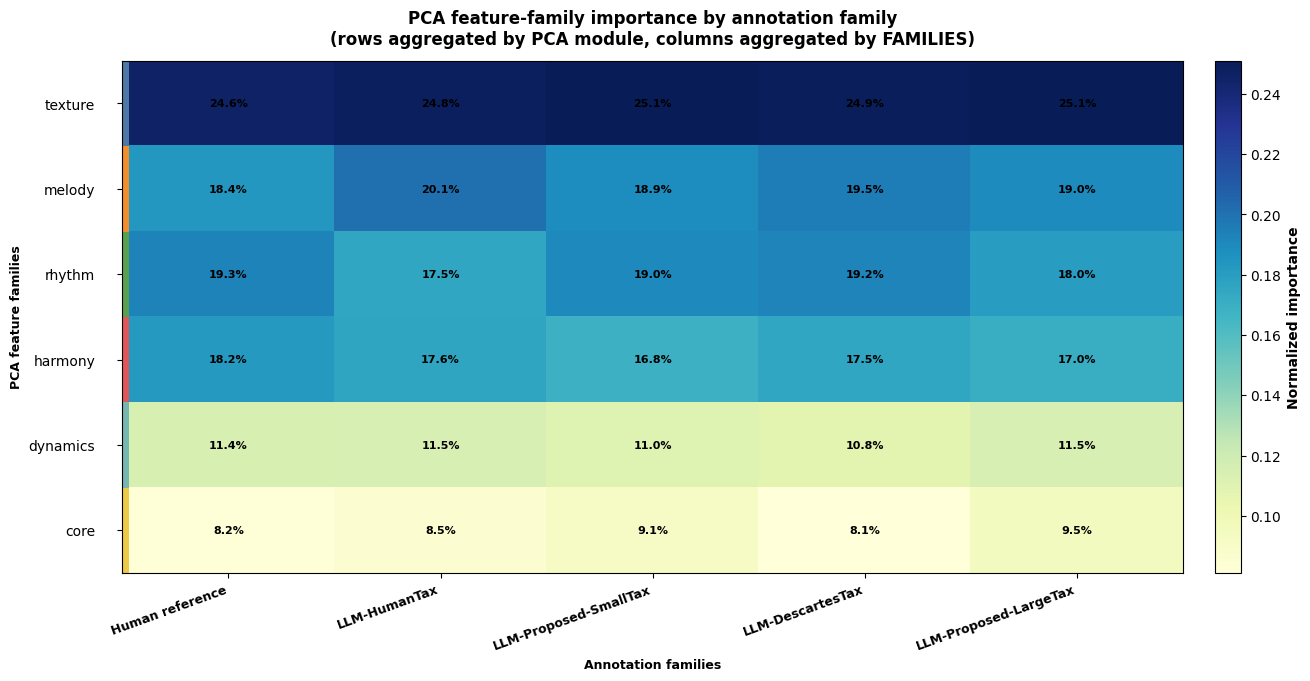

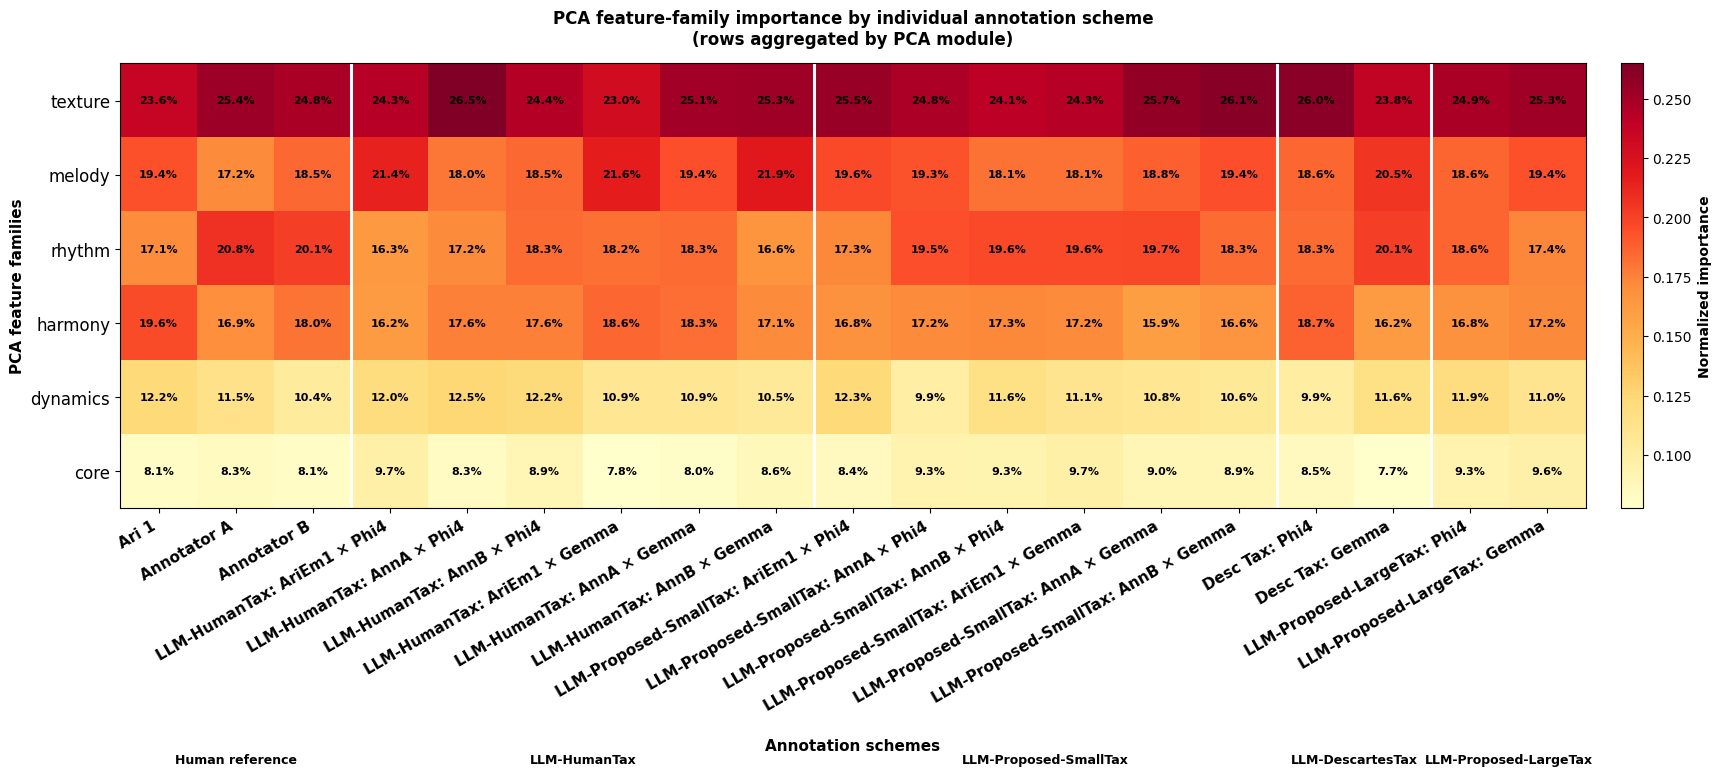

In [ ]:
from utils.importance_heatmaps import plot_module_importance

all_schemes = [s for family in FAMILIES.values() for s in family]

# 1) Family-aggregated view
plot_module_importance(
    module_store, FAMILIES, all_schemes,
    regex_map=module_regex_map, mode="family",
    normalize=True, annotate=True,
)

# 2) Per-scheme view
plot_module_importance(
    module_store, FAMILIES, all_schemes,
    regex_map=module_regex_map, mode="per_scheme",
    normalize=True, annotate=True,
)